# relxill fit of MARX-simulated Chandra spectrum ID 1000000081
### piled-up vs. unpiled, Sherpa (CIAO 4.17) + relxill, multiple optimizers

This notebook is a runnable walkthrough of the project documented in full
in `../CLAUDE.md` (methodology / decisions / Phases 1-5) and
`../results/report.md` (the complete fit-metrics report). It does not
repeat every decision made along the way -- see those two files for the
full reasoning, including why particular choices were made (statistic,
freezing stages, pileup parameters, etc).

**What this notebook does live**: loads the two spectra, builds the
`tbabs*relxill` (+ `jdpileup` for the piled case) models, fits the
literature-standard "Stage B" configuration for both spectra, and plots
the results.

**What it loads from disk instead of recomputing**: the full 24-combination
(2 spectra x 4 freezing stages x 3 optimizers) fit grid from Phase 4, and
the `conf`-vs-`covar` comparison from Phase 5 -- the former because several
of those combinations are slow (`moncar` in particular) and one
combination (piled, Stage A) crashes the Python process outright by
design of relxill's own error handling (see Phase 4 in `CLAUDE.md`), and
the latter because the piled spectrum's `conf` calculation alone takes
~40 minutes. Re-running `../scripts/run_fits.py` and
`../scripts/run_conf_flagship.py` reproduces those files if wanted.

In [1]:
import os
import sys
from pathlib import Path

NB_DIR = Path.cwd()
PROJECT_ROOT = NB_DIR.parent if (NB_DIR / "scripts").exists() is False else NB_DIR
# works whether the notebook is run from notebook/ or the project root
if (NB_DIR / "scripts").exists():
    PROJECT_ROOT = NB_DIR
else:
    PROJECT_ROOT = NB_DIR.parent

sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
os.environ.setdefault("RELXILL_TABLE_PATH", str(PROJECT_ROOT / "relxill" / "tables"))

%matplotlib inline
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from sherpa.astro import ui
import relxill.ui  # noqa: F401  registers xsumrelxill etc. with Sherpa

from load_data import setup_data, TARGET_ID
from build_models import (
    build_unpiled_model, build_piled_model, GROUND_TRUTH,
)

RESULTS = PROJECT_ROOT / "results"
print(f"project root: {PROJECT_ROOT}")
print(f"target spectrum ID: {TARGET_ID}")

Adding additive       XSPEC local model: xsumrelline


Adding convolution    XSPEC local model: xsumrelconv


Adding additive       XSPEC local model: xsumrelline_lp


Adding convolution    XSPEC local model: xsumrelconv_lp


Adding additive       XSPEC local model: xsumrelxill


Adding additive       XSPEC local model: xsumrelxilllp


... (6 outputs left out)

Adding additive       XSPEC local model: xsumrelline_ring


Adding additive       XSPEC local model: xsumrelxill_ring


Adding additive       XSPEC local model: xsumrelxill_ring_ecut


project root: /Users/juramaga/science/pileup/justina_fits
target spectrum ID: 1000000081


## Ground truth (simulation input parameters)

This is simulated data, so the true parameters used to generate spectrum
1000000081 are known (from `v0017_800ks_index.csv`) -- used here only to
*check* the fit afterwards, never fed into it as a starting value or
constraint (Stage D is a deliberate, explicitly-flagged exception -- see
`CLAUDE.md` Phase 3).

In [2]:
for k, v in GROUND_TRUTH.items():
    print(f"{k:10s} = {v}")

Afe        = 2.630883212688745
gamma      = 1.3305378369181775
incl       = 30.880998978376304
logxi      = 1.4965562318307917
nH         = 0.6496974978433812
norm       = 0.0972774295459766
refl_frac  = 14.314656850285886
spin       = 0.4929042376344323


## Load the two spectra (Phase 2)

`setup_data()` loads the unpiled and piled PHA files (written by
`../scripts/extract_spectrum.py` from the big MARX data table), attaches
their shared RMF/ARF, notices the 0.3-10 keV range (matches the response's
native energy grid), and sets the fit statistic to `cstat` (no background
spectrum exists for either PHA -- see `CLAUDE.md` Phase 2 for why `cstat`
over `wstat`/`chi2`).

In [3]:
id_unpiled, id_piled = setup_data()

for idname in (id_unpiled, id_piled):
    d = ui.get_data(idname)
    print(f"{idname:8s}  exposure={d.exposure:.0f}s  "
          f"counts(noticed)={d.get_dep(filter=True).sum():.0f}  "
          f"nbins(noticed)={d.get_dep(filter=True).size}")
print("statistic:", ui.get_stat_name())

read ARF file /Users/juramaga/science/pileup/justina_fits/responses/id1000000000_arf.fits


read RMF file /Users/juramaga/science/pileup/justina_fits/responses/c07_x222_y0531.rmf


read ARF file /Users/juramaga/science/pileup/justina_fits/responses/id1000000000_arf.fits


read RMF file /Users/juramaga/science/pileup/justina_fits/responses/c07_x222_y0531.rmf


dataset unpiled: 0.0073:14.9504 -> 0.292:10.001 Energy (keV)


dataset piled: 0.0073:14.9504 -> 0.292:10.001 Energy (keV)


unpiled   exposure=800000s  counts(noticed)=3708752  nbins(noticed)=665
piled     exposure=800000s  counts(noticed)=258118  nbins(noticed)=665
statistic: cstat


## Build the models (Phase 3)

- **Unpiled**: `xstbabs * xsumrelxill`
- **Piled**: same source model, wrapped with a `jdpileup` component via
  `set_pileup_model()` -- Sherpa inserts pileup (and folds the ARF in
  internally) between the source model and the RMF, which is where it
  physically belongs.

Both use **Stage B** here: the literature-standard freezing (`Rin=-1`
tied to the ISCO, `Rout=400`, single-power-law emissivity, `Ecut=300` keV
fixed -- a single CCD-resolution spectrum has essentially no leverage on
any of these). Free parameters: `nH, a, Incl, gamma, logxi, Afe,
refl_frac, norm` (+ pileup's `alpha, f` for the piled case). See
`CLAUDE.md` Phase 3 for the full Stage A-D ladder and the reasoning behind
each freeze -- this notebook only reproduces Stage B live; the other three
stages' results are loaded from disk further down.

In [4]:
STAGE = "B"

abs_u, rel_u = build_unpiled_model(id_unpiled, STAGE)
print("--- unpiled full model ---")
print(ui.get_model(id_unpiled))

--- unpiled full model ---
apply_rmf(apply_arf(800000.0 * xstbabs.abs_unpiled * xsumrelxill.refl_unpiled))
   Param        Type          Value          Min          Max      Units
   -----        ----          -----          ---          ---      -----
   abs_unpiled.nH thawed            1            0        1e+06 10^22 atoms / cm^2
   refl_unpiled.Index1 frozen            3          -10           10           
   refl_unpiled.Index2 frozen            3          -10           10           
   refl_unpiled.Rbr frozen           15            1         1000           
   refl_unpiled.a thawed        0.998       -0.998        0.998           
   refl_unpiled.Incl thawed           30            3           87        deg
   refl_unpiled.Rin frozen           -1         -100           -1           
   refl_unpiled.Rout frozen          400            1         1000           
   refl_unpiled.z frozen            0            0           10           
   refl_unpiled.gamma thawed            2   

In [5]:
abs_p, rel_p, pmod_p = build_piled_model(id_piled, STAGE)
print("--- piled full model ---")
print(ui.get_model(id_piled))

--- piled full model ---
apply_rmf(jdpileup.pileup_piled(xstbabs.abs_piled * xsumrelxill.refl_piled))
   Param        Type          Value          Min          Max      Units
   -----        ----          -----          ---          ---      -----
   pileup_piled.alpha thawed          0.5            0            1           
   pileup_piled.g0 frozen            1  1.17549e-38            1           
   pileup_piled.f thawed         0.95          0.9            1           
   pileup_piled.n frozen            1  1.17549e-38          100           
   pileup_piled.ftime frozen        3.241  1.17549e-38            5        sec
   pileup_piled.fracexp frozen        0.987            0            1           
   pileup_piled.nterms frozen           30            1          100           
   abs_piled.nH thawed            1            0        1e+06 10^22 atoms / cm^2
   refl_piled.Index1 frozen            3          -10           10           
   refl_piled.Index2 frozen            3        

## Fit Stage B live (Phase 4)

Using `levmar` for the unpiled spectrum and `neldermead` for the piled
one -- these are the methods that turned out to reach the best
*formally-converged* minimum for each spectrum at Stage B in the full
Phase 4 grid (see `../results/report.md`; `levmar` gets stuck in a poor
local minimum on the piled data at every stage, which is itself one of
the more interesting findings there).

In [6]:
ui.set_method("levmar")
ui.set_method_opt("maxfev", 1600)
ui.fit(id_unpiled)
fr_u = ui.get_fit_results()
print(fr_u)

Dataset               = unpiled
Method                = levmar
Statistic             = cstat
Initial fit statistic = 3.41412e+09
Final fit statistic   = 2054.5 at function evaluation 239
Data points           = 665
Degrees of freedom    = 657
Probability [Q-value] = 1.6006e-143
Reduced statistic     = 3.12709
Change in statistic   = 3.41412e+09
   abs_unpiled.nH   0.587234     +/- 0.00177917  
   refl_unpiled.a   0.477229     +/- 0.00508366  
   refl_unpiled.Incl   32.0515      +/- 0.058306    
   refl_unpiled.gamma   1.40581      +/- 0.00468603  
   refl_unpiled.logxi   1.00658      +/- 0.0325147   
   refl_unpiled.Afe   2.40094      +/- 0.0232024   
   refl_unpiled.refl_frac   23.6349      +/- 0.326813    
   refl_unpiled.norm   0.00185192   +/- 3.92793e-06 


datasets       = ('unpiled',)
itermethodname = none
methodname     = levmar
statname       = cstat
succeeded      = True
parnames       = ('abs_unpiled.nH', 'refl_unpiled.a', 'refl_unpiled.Incl', 'refl_unpiled.gamma', 'refl_unpiled.logxi', 'refl_unpiled.Afe', 'refl_unpiled.refl_frac', 'refl_unpiled.norm')
parvals        = (0.5872336609218345, 0.4772290302291942, 32.05146625217308, 1.405809795696857, 1.0065752125080656, 2.400940655106675, 23.634884398284917, 0.001851917567025237)
statval        = 2054.500184204369
istatval       = 3414118404.987219
dstatval       = 3414116350.487035
numpoints      = 665
dof            = 657
qval           = 1.6006041481364302e-143
rstat          = 3.127093126642875
message        = successful termination
nfev           = 239


In [7]:
ui.set_method("neldermead")
ui.set_method_opt("maxfev", 4000)
ui.fit(id_piled)  # ~40-60s
fr_p = ui.get_fit_results()
print(fr_p)

Dataset               = piled
Method                = neldermead
Statistic             = cstat
Initial fit statistic = 1.69967e+08
Final fit statistic   = 1039.89 at function evaluation 3990
Data points           = 665
Degrees of freedom    = 655
Probability [Q-value] = 5.43095e-20
Reduced statistic     = 1.58762
Change in statistic   = 1.69966e+08
   pileup_piled.alpha   0.34358     
   pileup_piled.f   0.992071    
   abs_piled.nH   0.694281    
   refl_piled.a   0.866015    
   refl_piled.Incl   31.6034     
   refl_piled.gamma   1.00004     
   refl_piled.logxi   2.30103     
   refl_piled.Afe   3.23304     
   refl_piled.refl_frac   19.1864     
   refl_piled.norm   0.0171812   


datasets       = ('piled',)
itermethodname = none
methodname     = neldermead
statname       = cstat
succeeded      = True
parnames       = ('pileup_piled.alpha', 'pileup_piled.f', 'abs_piled.nH', 'refl_piled.a', 'refl_piled.Incl', 'refl_piled.gamma', 'refl_piled.logxi', 'refl_piled.Afe', 'refl_piled.refl_frac', 'refl_piled.norm')
parvals        = (0.3435795681333325, 0.9920713814620246, 0.6942809685379578, 0.8660151032747868, 31.603416436463586, 1.0000366771633578, 2.301033928459773, 3.2330363094211303, 19.186429449666146, 0.01718123432978821)
statval        = 1039.8880904275497
istatval       = 169967025.01453623
dstatval       = 169965985.1264458
numpoints      = 665
dof            = 655
qval           = 5.430952279738477e-20
rstat          = 1.5876154052329003
message        = Optimization terminated successfully
nfev           = 3990


## Diagnostic plots: data, model, and ratio

/var/folders/57/n7hhtjss0tg3fjpkz6p_ds7r0000gn/T/ipykernel_29990/3420249975.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


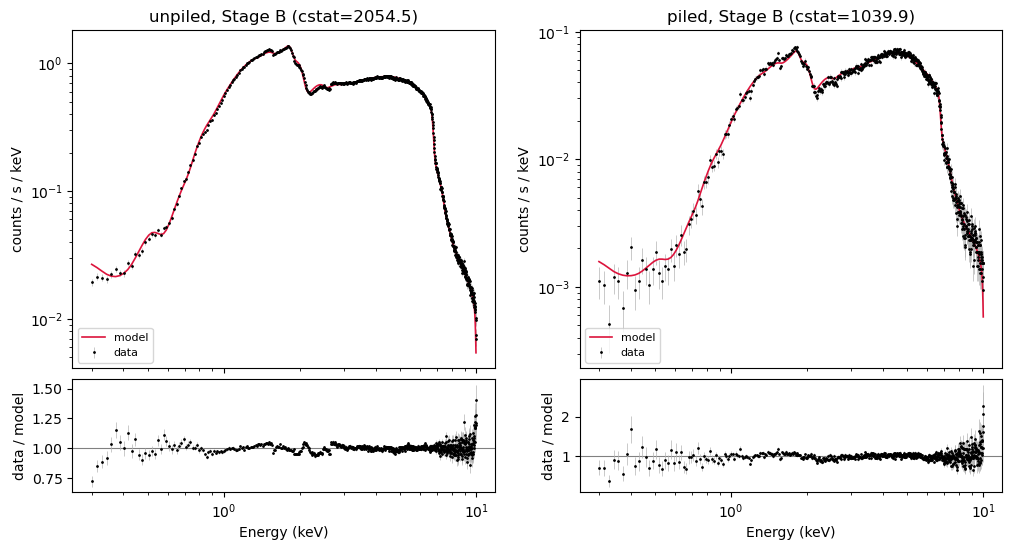

In [8]:
def plot_fit(fit_id, title, ax_top, ax_bot):
    dplot = ui.get_data_plot(fit_id)
    mplot = ui.get_model_plot(fit_id)
    rplot = ui.get_ratio_plot(fit_id)

    ax_top.errorbar(dplot.x, dplot.y, yerr=dplot.yerr, fmt=".", ms=2,
                     color="black", ecolor="0.7", elinewidth=0.5, label="data")
    ax_top.plot(mplot.x, mplot.y, color="crimson", lw=1.2, label="model")
    ax_top.set_yscale("log"); ax_top.set_xscale("log")
    ax_top.set_ylabel("counts / s / keV")
    ax_top.set_title(title)
    ax_top.legend(fontsize=8, loc="lower left")

    ax_bot.axhline(1.0, color="0.5", lw=0.8)
    ax_bot.errorbar(rplot.x, rplot.y, yerr=rplot.yerr, fmt=".", ms=2,
                     color="black", ecolor="0.7", elinewidth=0.5)
    ax_bot.set_xscale("log")
    ax_bot.set_ylabel("data / model"); ax_bot.set_xlabel("Energy (keV)")


fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex="col",
                           gridspec_kw=dict(height_ratios=[3, 1], hspace=0.05))
plot_fit(id_unpiled, f"unpiled, Stage B (cstat={fr_u.statval:.1f})",
         axes[0, 0], axes[1, 0])
plot_fit(id_piled, f"piled, Stage B (cstat={fr_p.statval:.1f})",
         axes[0, 1], axes[1, 1])
fig.tight_layout()
plt.show()

## Full Phase 4 grid (loaded from disk)

All 24 (spectrum x stage x method) combinations -- see `../CLAUDE.md`
Phase 4 for why this is loaded rather than recomputed live (runtime, and
the piled/Stage A crash). Each combination in the original run was
executed as its own subprocess for exactly that crash-safety reason.

In [9]:
def html_table(headers, rows):
    th = "".join(f"<th style='text-align:left;padding:2px 8px'>{h}</th>" for h in headers)
    trs = []
    for row in rows:
        tds = "".join(f"<td style='padding:2px 8px'>{c}</td>" for c in row)
        trs.append(f"<tr>{tds}</tr>")
    return f"<table><thead><tr>{th}</tr></thead><tbody>{''.join(trs)}</tbody></table>"


with open(RESULTS / "fits_raw.json") as f:
    raw = json.load(f)
records = raw["records"]

STAGES = ["A", "B", "C", "D"]
METHODS = ["levmar", "neldermead", "moncar"]

for spectrum in ("unpiled", "piled"):
    rows = []
    for stage in STAGES:
        for method in METHODS:
            r = next((r for r in records if r["spectrum"] == spectrum
                       and r["stage"] == stage and r["method"] == method), None)
            if r is None:
                continue
            if r.get("message") in ("CRASHED", "TIMEOUT", "PYTHON_EXCEPTION"):
                rows.append([stage, method, f"<b>{r['message']}</b>", "-", "-", "-", "-"])
                continue
            rows.append([stage, method, r.get("succeeded"),
                         f"{r.get('statval'):.1f}" if r.get('statval') is not None else "-",
                         f"{r.get('rstat'):.2f}" if r.get('rstat') is not None else "-",
                         r.get("nfev"), f"{r.get('wall_time_s'):.1f}"])
    display(HTML(f"<h4>{spectrum}</h4>"))
    display(HTML(html_table(
        ["stage", "method", "converged", "cstat", "reduced stat", "nfev", "time (s)"],
        rows)))

stage,method,converged,cstat,reduced stat,nfev,time (s)
A,levmar,True,97330.8,149.51,414,3.0
A,neldermead,True,3537.7,5.43,5598,36.8
A,moncar,False,3117.3,4.79,9800,62.1
B,levmar,True,2054.5,3.13,239,1.6
B,neldermead,False,2052.9,3.12,3212,20.8
B,moncar,False,2184.8,3.33,5600,34.9
C,levmar,True,6017.1,9.14,312,2.1
C,neldermead,False,6013.4,9.14,2811,16.8
C,moncar,False,6713.2,10.20,4900,41.7
D,levmar,True,6139.4,9.32,306,1.8


stage,method,converged,cstat,reduced stat,nfev,time (s)
A,levmar,CRASHED,-,-,-,-
A,neldermead,CRASHED,-,-,-,-
A,moncar,CRASHED,-,-,-,-
B,levmar,True,76025.9,116.07,542,4.6
B,neldermead,True,1039.9,1.59,3990,50.5
B,moncar,False,1010.7,1.54,7000,76.6
C,levmar,True,76984.8,117.35,755,7.5
C,neldermead,False,1315.1,2.00,3622,51.0
C,moncar,False,1128.5,1.72,6300,77.1
D,levmar,True,76572.4,116.55,501,5.1


Note the three `CRASHED` rows for piled/Stage A: relxill's C++ code
calls a hard, uncatchable process abort on an unphysical `Rout<=Rin`
parameter excursion, which all three optimizers hit when given the full
15-parameter freedom of Stage A on the piled model. This is not
reproduced live in this notebook for the obvious reason that it would
take the kernel down with it -- see `CLAUDE.md` Phase 4 for the full
account, including why this is treated as a genuine finding (Stage A is
numerically intractable for the piled spectrum, not just poorly
constrained) rather than a bug to silently work around.

## Ground-truth comparison and conf-vs-covar (Phase 5, loaded from disk)

`results/analysis_summary.json` has the best-fit-vs-truth comparison for
every stage; `results/conf_flagship.json` has the profile-likelihood
(`conf`) vs. covariance-matrix (`covar`) comparison for the Stage B
flagship fits shown above. See `../results/report.md` for the full
discussion -- this cell reproduces just the Stage B numbers relevant to
the fit above.

In [10]:
with open(RESULTS / "analysis_summary.json") as f:
    summary = json.load(f)

gt_labels = {"a": "spin (a)", "Incl": "Incl (deg)", "gamma": "gamma",
             "logxi": "logxi", "Afe": "Afe", "refl_frac": "refl_frac",
             "nH": "nH (1e22 cm^-2)"}

for spectrum in ("unpiled", "piled"):
    comp = summary["ground_truth_comparison"][f"{spectrum}/B"]["comparison"]
    rows = []
    for short, label in gt_labels.items():
        c = comp.get(short)
        if c is None:
            continue
        rows.append([label, f"{c['fitted']:.4g}", f"{c['truth']:.4g}",
                     f"{c['rel_diff_pct']:.1f}%"])
    display(HTML(f"<h4>{spectrum}, Stage B vs. ground truth</h4>"))
    display(HTML(html_table(["parameter", "fitted", "truth", "rel. diff"], rows)))

parameter,fitted,truth,rel. diff
spin (a),0.4772,0.4929,-3.2%
Incl (deg),32.05,30.88,3.8%
gamma,1.406,1.331,5.7%
logxi,1.007,1.497,-32.7%
Afe,2.401,2.631,-8.7%
refl_frac,23.63,14.31,65.1%
nH (1e22 cm^-2),0.5872,0.6497,-9.6%


parameter,fitted,truth,rel. diff
spin (a),0.866,0.4929,75.7%
Incl (deg),31.6,30.88,2.3%
gamma,1,1.331,-24.8%
logxi,2.301,1.497,53.8%
Afe,3.233,2.631,22.9%
refl_frac,19.19,14.31,34.0%
nH (1e22 cm^-2),0.6943,0.6497,6.9%


In [11]:
with open(RESULTS / "conf_flagship.json") as f:
    conf_flag = json.load(f)

for spectrum in ("unpiled", "piled"):
    flag = conf_flag[spectrum]
    rows = []
    for name, val, clo, chi, klo, khi in zip(
            flag["parnames"], flag["parvals"],
            flag["covar_parmins"], flag["covar_parmaxes"],
            flag["conf_parmins"], flag["conf_parmaxes"]):
        short = name.split(".")[-1]
        covar_s = "undefined" if clo is None or chi is None else f"[{clo:+.4g}, {chi:+.4g}]"
        klo_s = "(boundary)" if klo is None else f"{klo:+.4g}"
        khi_s = "(boundary)" if khi is None else f"{khi:+.4g}"
        conf_s = "undefined" if klo is None and khi is None else f"[{klo_s}, {khi_s}]"
        rows.append([short, f"{val:.4g}", covar_s, conf_s])
    display(HTML(f"<h4>{spectrum}, Stage B: covar vs. conf "
                   f"(covar {flag['covar_time_s']:.1f}s, conf {flag['conf_time_s']:.1f}s)</h4>"))
    display(HTML(html_table(["parameter", "best fit", "covar 1-sigma", "conf 1-sigma"], rows)))

parameter,best fit,covar 1-sigma,conf 1-sigma
nH,0.5872,"[-0.001986, +0.001986]","[-0.002979, +0.003739]"
a,0.4772,"[-7.718e-05, +7.718e-05]","[-0.005485, +0.01061]"
Incl,32.05,"[-0.03588, +0.03588]","[-0.1143, +0.104]"
gamma,1.406,"[-0.001968, +0.001968]","[-0.01067, +0.002983]"
logxi,1.007,"[-0.02858, +0.02858]","[-0.01494, +0.08126]"
Afe,2.401,"[-0.01829, +0.01829]","[-0.01997, +0.04944]"
refl_frac,23.63,"[-0.2048, +0.2048]","[-0.6922, +0.1862]"
norm,0.001852,"[-1.594e-06, +1.594e-06]","[-4.861e-06, +8.486e-06]"


parameter,best fit,covar 1-sigma,conf 1-sigma
alpha,0.3436,undefined,undefined
f,0.9921,undefined,"[(boundary), +0.007896]"
nH,0.6943,undefined,"[-0.01125, +0.01362]"
a,0.866,undefined,"[-0.0125, +0.0139]"
Incl,31.6,undefined,"[-0.574, +0.289]"
gamma,1,undefined,"[(boundary), +0.1857]"
logxi,2.301,undefined,"[(boundary), +0.01856]"
Afe,3.233,undefined,"[-0.1681, +0.1361]"
refl_frac,19.19,undefined,"[-0.7167, +0.249]"
norm,0.01718,undefined,"[-0.01309, +0.01828]"


## Summary

- Both spectra fit reasonably well visually (few-percent residuals across
  most of the 0.3-10 keV band) at Stage B, despite reduced stat > 1 in
  both cases -- with millions of counts, `cstat` has enough statistical
  power to detect small systematic mismatches that wouldn't show up in a
  lower-count spectrum.
- `conf` and `covar` genuinely disagree, and `covar` failed outright on
  the piled fit -- don't trust `covar` alone on a highly nonlinear,
  many-parameter model like this.
- The progressive freezing ladder (Stage A -> D) is not just a
  dimensionality-reduction convenience: Stage A is numerically
  intractable for the piled spectrum (hard crash, all three optimizers),
  and Stage C's "standard" solar-abundance assumption actively hurts the
  fit for this particular (super-solar Afe) simulated source.

Full discussion, all four stages, and the pileup-bias comparison:
`../results/report.md`. Full methodology and decision log: `../CLAUDE.md`.
Didactic write-up: `../writeup/`.